## **LAB - 2**
## **Name - Shubhi Kumari**
## **Section - C-C3-34**

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn import metrics

In [ ]:
df = pd.read_csv("/content/USA_Housing.csv")

In [ ]:
df.head()

,Avg. Area Income,Avg. Area House Age,Avg. Area Number of Rooms,Avg. Area Number of Bedrooms,Area Population,Price,Address
0,79545.46,5.68,7.01,4.09,23086.80,1059033.56,"208 Michael Ferry Apt. 674\nLaurabury, NE 3701..."
1,79248.64,6.00,6.73,3.09,40173.07,1505890.91,"188 Johnson Views Suite 079\nLake Kathleen, CA..."
2,61287.07,5.87,8.51,5.13,36882.16,1058987.99,"9127 Elizabeth Stravenue\nDanieltown, WI 06482..."
3,63345.24,7.19,5.59,3.26,34310.24,1260616.81,USS Barnett\nFPO AP 44820
4,59982.20,5.04,7.84,4.23,26354.11,630943.49,USNS Raymond\nFPO AE 09386


In [ ]:
df.tail()

,Avg. Area Income,Avg. Area House Age,Avg. Area Number of Rooms,Avg. Area Number of Bedrooms,Area Population,Price,Address
4995,60567.94,7.83,6.14,3.46,22837.36,1060193.79,USNS Williams\nFPO AP 30153-7653
4996,78491.28,7.00,6.58,4.02,25616.12,1482617.73,"PSC 9258, Box 8489\nAPO AA 42991-3352"
4997,63390.69,7.25,4.81,2.13,33266.15,1030729.58,"4215 Tracy Garden Suite 076\nJoshualand, VA 01..."
4998,68001.33,5.53,7.13,5.44,42625.62,1198656.87,USS Wallace\nFPO AE 73316
4999,65510.58,5.99,6.79,4.07,46501.28,1298950.48,"37778 George Ridges Apt. 509\nEast Holly, NV 2..."


In [ ]:
df.describe()

,Avg. Area Income,Avg. Area House Age,Avg. Area Number of Rooms,Avg. Area Number of Bedrooms,Area Population,Price
count,5000.00,5000.00,5000.00,5000.00,5000.00,5000.00
mean,68583.11,5.98,6.99,3.98,36163.52,1232072.65
std,10657.99,0.99,1.01,1.23,9925.65,353117.63
min,17796.63,2.64,3.24,2.00,172.61,15938.66
25%,61480.56,5.32,6.30,3.14,29403.93,997577.14
50%,68804.29,5.97,7.00,4.05,36199.41,1232669.38
75%,75783.34,6.65,7.67,4.49,42861.29,1471210.20
max,107701.75,9.52,10.76,6.50,69621.71,2469065.59


In [ ]:
print(df.shape)

(5000, 7)


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 7 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Avg. Area Income              5000 non-null   float64
 1   Avg. Area House Age           5000 non-null   float64
 2   Avg. Area Number of Rooms     5000 non-null   float64
 3   Avg. Area Number of Bedrooms  5000 non-null   float64
 4   Area Population               5000 non-null   float64
 5   Price                         5000 non-null   float64
 6   Address                       5000 non-null   object 
dtypes: float64(6), object(1)
memory usage: 273.6+ KB


In [ ]:
df.isnull().sum()

,0
Avg. Area Income,0
Avg. Area House Age,0
Avg. Area Number of Rooms,0
Avg. Area Number of Bedrooms,0
Area Population,0
Price,0
Address,0


In [ ]:
df.isnull()

,Avg. Area Income,Avg. Area House Age,Avg. Area Number of Rooms,Avg. Area Number of Bedrooms,Area Population,Price,Address
0,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...
4995,False,False,False,False,False,False,False
4996,False,False,False,False,False,False,False
4997,False,False,False,False,False,False,False
4998,False,False,False,False,False,False,False


In [ ]:
df.drop("Address",axis=1,inplace=True)

In [ ]:
df.isnull().sum()

,0
Avg. Area Income,0
Avg. Area House Age,0
Avg. Area Number of Rooms,0
Avg. Area Number of Bedrooms,0
Area Population,0
Price,0


In [ ]:
pd.set_option('display.float_format','{:.2f}'.format)

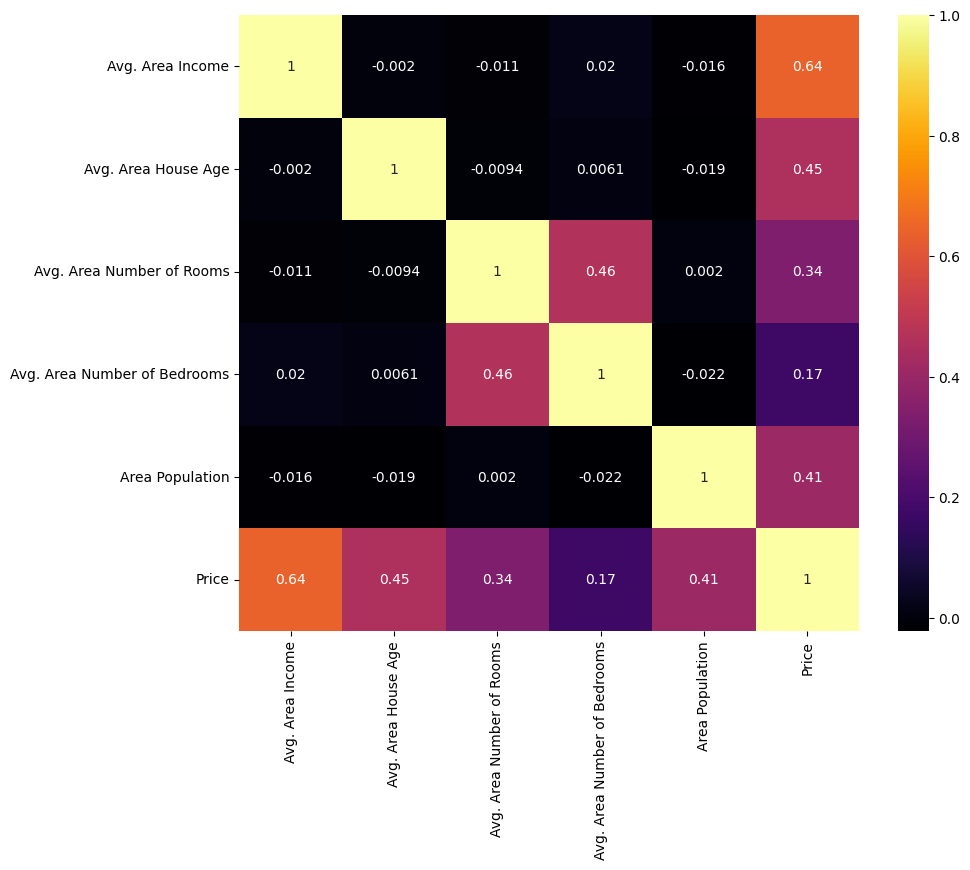

In [ ]:
plt.figure(figsize = (10,8))

numeric_df = df.select_dtypes(include=['number'])

sns.heatmap(numeric_df.corr(),
            annot=True,
            cmap = 'inferno')
plt.show()

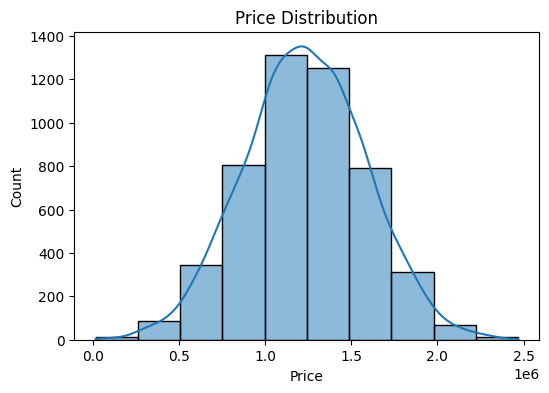

In [ ]:
plt.figure(figsize=(6,4))
sns.histplot(df["Price"],bins=10,kde =True)  # bins = interval , kde = kernel density estimation

plt.title("Price Distribution")
plt.show()

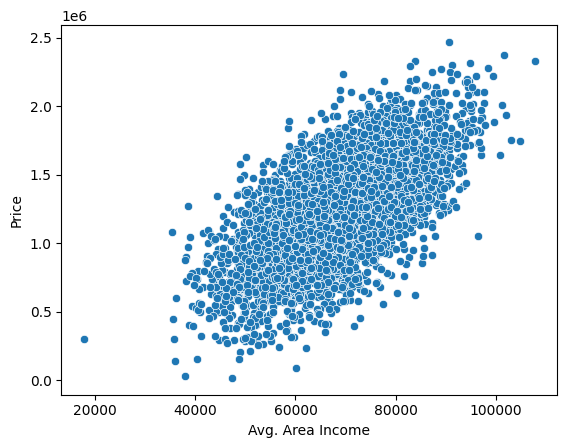

In [ ]:
sns.scatterplot(x="Avg. Area Income",y="Price",data=df)
plt.show()

In [ ]:
Q1 = df["Price"].quantile(0.25)
Q3 = df["Price"].quantile(0.75)

IQR = Q3 - Q1
lower = Q1 - 1.5*IQR
upper = Q3 + 1.5*IQR

df = df[(df["Price"]>=lower) & (df["Price"] <= upper)]

In [ ]:
X = df[["Avg. Area Income"]]
y= df["Price"]

X_train, X_test, y_train, y_test = train_test_split(X,y,test_size = 0.2, random_state= 42)

In [ ]:
slr_model = LinearRegression()
slr_model.fit(X_train, y_train)

LinearRegression()

In [ ]:
y_pred = slr_model.predict(X_test)

In [ ]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

print("Simple Linear Rgression Results")
print("------------------------------")
print("MAE: ",mean_absolute_error(y_test,y_pred))
print("MSE: ",mean_squared_error(y_test,y_pred))
print("RMSE: ",np.sqrt(mean_squared_error(y_test,y_pred)))
print("R2 Score: ",r2_score(y_test,y_pred))

Simple Linear Rgression Results
------------------------------
MAE:  211937.1651550006
MSE:  69064771104.78278
RMSE:  262801.77150236786
R2 Score:  0.3694634636084436


In [ ]:
print("Intercept:",slr_model.intercept_)
print("Slope:",slr_model.coef_[0])

Intercept: -184980.2982096942
Slope: 20.653526141857427


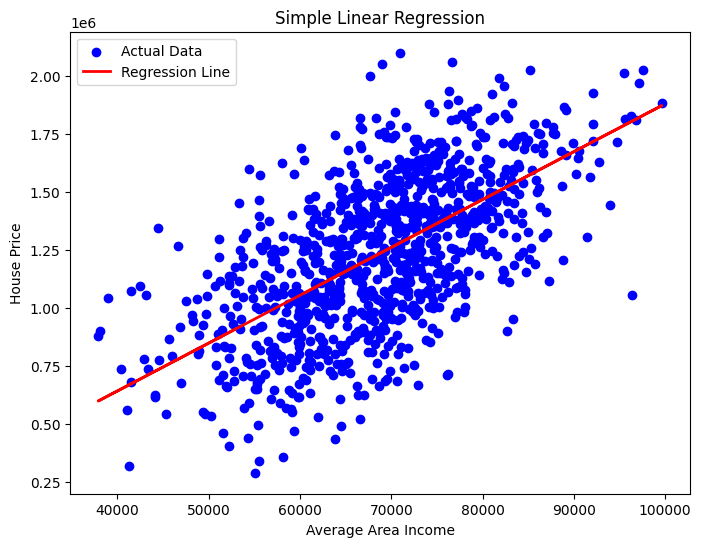

In [ ]:
plt.figure(figsize=(8,6))
plt.scatter(X_test,y_test,color = 'blue',label = 'Actual Data')
plt.plot(X_test,y_pred,color='red',linewidth =2,label ='Regression Line')

plt.xlabel("Average Area Income")
plt.ylabel("House Price")
plt.title("Simple Linear Regression")
plt.legend()

plt.show()

In [ ]:
income = float(input("Enter Average Area Income: "))
new_data = np.array([[income]])
prediction = slr_model.predict(new_data)
print("Predicted House Price = ${:,.2f}".format(prediction[0]))

Enter Average Area Income: 1500000
Predicted House Price = $30,795,308.91


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


### **HYPERPARAMETERS TUNNING (Ridge Regression)**

In [ ]:
from sklearn.model_selection import GridSearchCV

In [ ]:
from sklearn.linear_model import Ridge
ridge = Ridge()
ridge.fit(X_train,y_train)
ridge_pred = ridge.predict(X_test)
print("Default Ridge R^2: ",r2_score(y_test,ridge_pred))

Default Ridge R^2:  0.3694634636085241


In [ ]:
param_grid = {'alpha': [0.001,0.01,0.1,0,10,100]}

In [ ]:
grid_ridge = GridSearchCV(estimator = Ridge(),param_grid = param_grid,scoring ='r2',cv = 5)

In [ ]:
grid_ridge.fit(X_train,y_train)

GridSearchCV(cv=5, estimator=Ridge(),
             param_grid={'alpha': [0.001, 0.01, 0.1, 0, 10, 100]},
             scoring='r2')

In [ ]:
print("Best Alpha: ", grid_ridge.best_params_)

Best Alpha:  {'alpha': 100}


In [ ]:
print(grid_ridge.best_score_)

0.3981241355959155


In [ ]:
best_ridge = grid_ridge.best_estimator_
ridge_pred = best_ridge.predict(X_test)

In [ ]:
print("MAE: " , mean_absolute_error(y_test,ridge_pred))
print("MSE: " , mean_squared_error(y_test,ridge_pred))
print("RMSE: " , np.sqrt(mean_squared_error(y_test,ridge_pred)))
print("R2 Score: " , r2_score(y_test,ridge_pred))

MAE:  211937.16515469394
MSE:  69064771103.9007
RMSE:  262801.7715006897
R2 Score:  0.3694634636164965


### **MULTIPLE LINEAR REGRESSION**

In [ ]:
mlr_model = LinearRegression()
mlr_model.fit(X_train, y_train)

LinearRegression()

In [ ]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

print("Multiple Linear Rgression Results")
print("------------------------------")
print("MAE: ",mean_absolute_error(y_test,y_pred))
print("MSE: ",mean_squared_error(y_test,y_pred))
print("RMSE: ",np.sqrt(mean_squared_error(y_test,y_pred)))
print("R2 Score: ",r2_score(y_test,y_pred))

Multiple Linear Rgression Results
------------------------------
MAE:  211937.1651550006
MSE:  69064771104.78278
RMSE:  262801.77150236786
R2 Score:  0.3694634636084436


In [ ]:
print("Intercept:", mlr_model.intercept_)

# Check if X has multiple columns for multiple linear regression
if len(X.columns) > 1:
    print("\nCoefficients (Slopes) for each feature:")
    for i, col in enumerate(X.columns):
        print(f"{col}: {mlr_model.coef_[i]}")
else:
    print("\nSlope (for Simple Linear Regression):")
    print(f"{X.columns[0]}: {mlr_model.coef_[0]}")

Intercept: -184980.2982096942
Slope: 20.653526141857427
